In [1]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
real_estate = fetch_ucirepo(id=477)

X = real_estate.data.features
y = real_estate.data.targets

df = pd.concat([X, y], axis=1)

In [4]:
df['transaction_date'] = pd.to_datetime(
    df['X1 transaction date'].astype(str),
    format='%Y.%f'
)

In [5]:
year = np.floor(df['X1 transaction date']).astype(int)

fraction = df['X1 transaction date'] - year

days = (fraction * 365.25).round().astype(int)

df['transaction_date'] = (
    pd.to_datetime(year.astype(str), format='%Y')
    + pd.to_timedelta(days, unit='D')
)

In [7]:
df.head(10)

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area,transaction_date
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9,2012-12-01
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2,2012-12-01
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3,2013-08-02
3,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8,2013-07-03
4,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1,2012-10-31
5,2012.667,7.1,2175.03000,3,24.96305,121.51254,32.1,2012-09-01
6,2012.667,34.5,623.47310,7,24.97933,121.53642,40.3,2012-09-01
7,2013.417,20.3,287.60250,6,24.98042,121.54228,46.7,2013-06-02
8,2013.500,31.7,5512.03800,1,24.95095,121.48458,18.8,2013-07-03
9,2013.417,17.9,1783.18000,3,24.96731,121.51486,22.1,2013-06-02


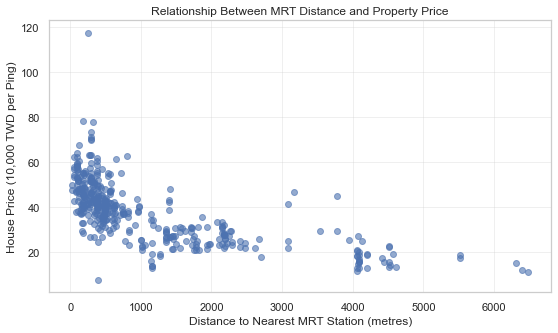

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.scatter(
    df['X3 distance to the nearest MRT station'],
    df['Y house price of unit area'],
    alpha=0.6
)

plt.title('Relationship Between MRT Distance and Property Price')
plt.xlabel('Distance to Nearest MRT Station (metres)')
plt.ylabel('House Price (10,000 TWD per Ping)')
plt.grid(alpha=0.3)
plt.show()

In [19]:
distance = 'X3 distance to the nearest MRT station'
price = 'Y house price of unit area'

# Pearson correlation
pearson_corr = df[distance].corr(df[price], method='pearson')

# Spearman correlation
spearman_corr = df[distance].corr(df[price], method='spearman')

print("Pearson correlation:", pearson_corr)
print("Spearman correlation:", spearman_corr)

Pearson correlation: -0.6736128553689184
Spearman correlation: -0.7759483354370685


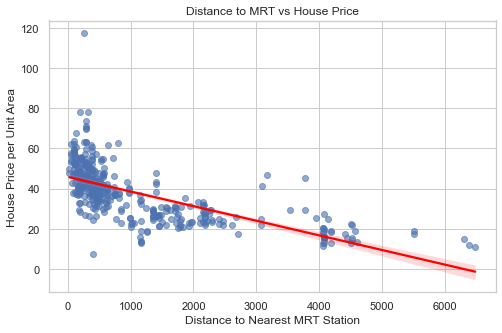

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x='X3 distance to the nearest MRT station',
    y='Y house price of unit area',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title('Distance to MRT vs House Price')
plt.xlabel('Distance to Nearest MRT Station')
plt.ylabel('House Price per Unit Area')
plt.show()

In [23]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# =====================================================
# 1. DEFINE THE VARIABLES
# =====================================================

target = 'Y house price of unit area'

# Model 1: Age + MRT distance + Convenience stores
# Model 2: Age + MRT distance + Convenience stores + Latitude + Longitude
# Model 3: Age + Convenience stores + Latitude + Longitude
# Model 4: Age + MRT distance + Convenience stores + Latitude

models = {
    'Model 1': f'Q("{target}") ~ Q("X2 house age") + Q("X3 distance to the nearest MRT station") + Q("X4 number of convenience stores")',

    'Model 2': f'Q("{target}") ~ Q("X2 house age") + Q("X3 distance to the nearest MRT station") + Q("X4 number of convenience stores") + Q("X5 latitude") + Q("X6 longitude")',

    'Model 3': f'Q("{target}") ~ Q("X2 house age") + Q("X4 number of convenience stores") + Q("X5 latitude") + Q("X6 longitude")',

    'Model 4': f'Q("{target}") ~ Q("X2 house age") + Q("X3 distance to the nearest MRT station") + Q("X4 number of convenience stores") + Q("X5 latitude")'
}

# =====================================================
# 2. COMPARE THE FOUR ORIGINAL MODELS
# =====================================================

comparison = []

for name, formula in models.items():
    fitted_model = smf.ols(formula, data=df).fit()

    comparison.append({
        'Model': name,
        'R-squared': fitted_model.rsquared,
        'Adjusted R-squared': fitted_model.rsquared_adj,
        'AIC': fitted_model.aic,
        'BIC': fitted_model.bic
    })

comparison_df = pd.DataFrame(comparison)

print("MODEL COMPARISON")
print(comparison_df.round(4))

# Identify the model with the highest Adjusted R-squared
best_model = comparison_df.loc[
    comparison_df['Adjusted R-squared'].idxmax()
]

print("\nMODEL SELECTION")
print(f"Selected model: {best_model['Model']}")
print(f"Highest Adjusted R-squared: {best_model['Adjusted R-squared']:.4f}")

# =====================================================
# 3. FIT MODEL 4 AND LOG-TRANSFORMED MODEL 4
# =====================================================

model4_formula = models['Model 4']

# Use the same train-test split for a fair comparison
train, test = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

# Original Model 4
model4 = smf.ols(model4_formula, data=train).fit()

# Log-transformed Model 4
log_formula = model4_formula.replace(
    f'Q("{target}")',
    f'np.log(Q("{target}"))'
)

log_model4 = smf.ols(log_formula, data=train).fit()

# =====================================================
# 4. MAKE PREDICTIONS
# =====================================================

y_test = test[target]

# Original model predictions
pred_original = model4.predict(test)

# Log model predictions
pred_log = log_model4.predict(test)

# Duan smearing correction to reduce retransformation bias
smearing_factor = np.mean(np.exp(log_model4.resid))

pred_log_original_scale = np.exp(pred_log) * smearing_factor

# =====================================================
# 5. COMPARE MODEL PERFORMANCE
# =====================================================

results = pd.DataFrame({
    'Model': ['Original Model 4', 'Log-transformed Model 4'],

    'R-squared': [
        r2_score(y_test, pred_original),
        r2_score(y_test, pred_log_original_scale)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, pred_original)),
        np.sqrt(mean_squared_error(y_test, pred_log_original_scale))
    ],

    'MAE': [
        mean_absolute_error(y_test, pred_original),
        mean_absolute_error(y_test, pred_log_original_scale)
    ]
})

print("\nTEST SET PERFORMANCE COMPARISON")
print(results.round(4))

# =====================================================
# 6. FINAL INTERPRETATION
# =====================================================

print("\nMODEL 4 SUMMARY")
print(model4.summary())

print("\nLOG-TRANSFORMED MODEL 4 SUMMARY")
print(log_model4.summary())

MODEL COMPARISON
     Model  R-squared  Adjusted R-squared        AIC        BIC
0  Model 1     0.5411              0.5377  3020.9716  3037.0750
1  Model 2     0.5712              0.5659  2996.8890  3021.0442
2  Model 3     0.5347              0.5302  3028.6539  3048.7832
3  Model 4     0.5711              0.5669  2994.9146  3015.0439

MODEL SELECTION
Selected model: Model 4
Highest Adjusted R-squared: 0.5669

TEST SET PERFORMANCE COMPARISON
                     Model  R-squared    RMSE     MAE
0         Original Model 4     0.6763  7.3694  5.3510
1  Log-transformed Model 4     0.7129  6.9406  4.7489

MODEL 4 SUMMARY
                                   OLS Regression Results                                  
Dep. Variable:     Q("Y house price of unit area")   R-squared:                       0.546
Model:                                         OLS   Adj. R-squared:                  0.540
Method:                              Least Squares   F-statistic:                     97.83
Date:  